# 06 · Statistical Analysis

**Do physiological responses differ between acute stress, aerobic and anaerobic exercise, and by how much?**

Design principles:
- **The participant is the unit.** Windows are averaged within participant × state; tests and CIs are computed across
  participants. 30 participants have all three protocols, so most comparisons are **paired (within-subject)**.
- **Effect sizes first:** mean paired difference with a bootstrap 95% CI, and Cohen's d_z. p-values (Wilcoxon
  signed-rank) are Holm-corrected within each family.
- **Mixed models** (random intercept per participant, cohort as covariate) confirm the paired results while using every
  participant, including those with incomplete data.
- **Caveat that applies throughout:** the only seated resting reference is on the *stress* day. Exercise-vs-rest
  contrasts include day-to-day variability. Stress-vs-rest contrasts are same-day.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.visualization import plots as P

P.set_style()
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
PROCESSED = ROOT / "data" / "processed"; INTERIM = ROOT / "data" / "interim"
C = P.COND_COLORS

from src.signals.quality import masked_features
from src.models.stats import paired_effect, pairwise_states, mixed_model, icc_within_state, repeated_measures_corr, holm
from src.models.classify import FEATURE_LABELS

w = pd.read_csv(PROCESSED / "windows.csv")
m = masked_features(w)
m["eda_log"] = np.log10(m.eda_tonic_mean.clip(lower=0.01))
FEATS = ["hr_mean", "eda_log", "eda_scr_rate", "temp_slope", "acc_movement"]
FL = {**FEATURE_LABELS, "eda_log": "EDA tonic (log10 µS)"}
STATES = ["REST_SEATED", "STRESS_TMCT", "STRESS_RECOVERY", "AEROBIC_MODERATE", "AEROBIC_PEAK", "SPRINT", "POST_SPRINT", "POST_EXERCISE_REST"]
LABEL = {"REST_SEATED": "Seated rest", "STRESS_TMCT": "Stress (TMCT)", "STRESS_RECOVERY": "Stress recovery",
         "AEROBIC_MODERATE": "Aerobic moderate", "AEROBIC_PEAK": "Aerobic peak", "SPRINT": "Sprint",
         "POST_SPRINT": "Post-sprint 0-2 min", "POST_EXERCISE_REST": "Post-exercise rest"}
SCOL = {"STRESS_TMCT": C["STRESS"], "STRESS_RECOVERY": C["STRESS"], "AEROBIC_MODERATE": C["AEROBIC"], "AEROBIC_PEAK": C["AEROBIC"],
        "SPRINT": C["ANAEROBIC"], "POST_SPRINT": C["ANAEROBIC"], "POST_EXERCISE_REST": P.TEXT_2}
pm = m[m.analysis_state.isin(STATES)].groupby(["subject_id", "cohort", "analysis_state"])[FEATS].mean().reset_index()
pm = pm.rename(columns={"analysis_state": "state"})
print(pm.groupby("state").subject_id.nunique().reindex(STATES))

state
REST_SEATED           36
STRESS_TMCT           36
STRESS_RECOVERY       36
AEROBIC_MODERATE      30
AEROBIC_PEAK          30
SPRINT                31
POST_SPRINT           31
POST_EXERCISE_REST    31
Name: subject_id, dtype: int64


## 1 · Change from seated rest, every signal, every state

Paired difference (state − seated rest) per participant. Dot = mean, bar = bootstrap 95% CI, n = participants with both
values. States with < 10 participants are omitted.

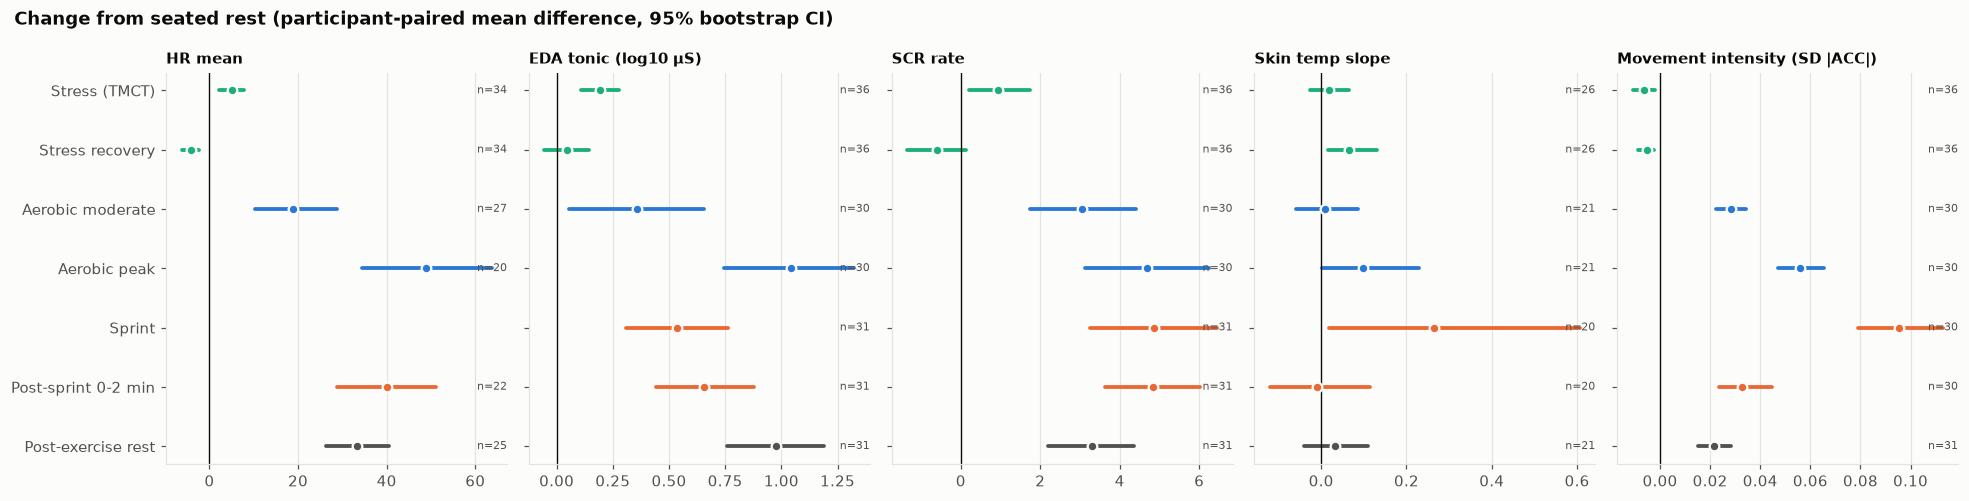

,feature,state,n,mean_diff,ci_low,ci_high,dz,p_holm
0,hr_mean,STRESS_TMCT,34,5.000,2.177,7.773,0.601,0.002
1,hr_mean,STRESS_RECOVERY,34,-4.269,-6.274,-2.376,-0.719,0.001
2,hr_mean,AEROBIC_MODERATE,27,18.899,10.200,28.828,0.742,0.001
3,hr_mean,AEROBIC_PEAK,20,48.787,34.335,63.664,1.401,0.000
4,hr_mean,POST_SPRINT,22,40.086,28.713,51.081,1.445,0.000
5,hr_mean,POST_EXERCISE_REST,25,33.248,26.362,40.487,1.826,0.000
6,eda_log,STRESS_TMCT,36,0.192,0.107,0.277,0.741,0.001
7,eda_log,STRESS_RECOVERY,36,0.044,-0.055,0.142,0.145,0.252
8,eda_log,AEROBIC_MODERATE,30,0.357,0.057,0.657,0.426,0.062
9,eda_log,AEROBIC_PEAK,30,1.043,0.743,1.324,1.297,0.000


In [2]:
rows = []
for f in FEATS:
    wide = pm.pivot_table(index="subject_id", columns="state", values=f)
    for s in STATES[1:]:
        if s not in wide: continue
        d = wide[["REST_SEATED", s]].dropna()
        if len(d) < 10: continue
        rows.append(dict(feature=f, state=s, **paired_effect(d.REST_SEATED.to_numpy(), d[s].to_numpy())))
vs_rest = pd.DataFrame(rows)
vs_rest["p_holm"] = vs_rest.groupby("feature").p_wilcoxon.transform(holm)
vs_rest.to_csv(PROCESSED / "stats_vs_rest.csv", index=False)

fig, axes = plt.subplots(1, len(FEATS), figsize=(18, 4.6), sharey=True)
order = [s for s in STATES[1:]]
for ax, f in zip(axes, FEATS):
    d = vs_rest[vs_rest.feature == f].set_index("state").reindex(order)
    y = np.arange(len(order))
    for i, s in enumerate(order):
        if not np.isfinite(d.loc[s, "mean_diff"]): continue
        ax.plot([d.loc[s, "ci_low"], d.loc[s, "ci_high"]], [i, i], color=SCOL[s], lw=2.5, solid_capstyle="round")
        ax.scatter(d.loc[s, "mean_diff"], i, color=SCOL[s], s=40, zorder=3, edgecolor=P.SURFACE, lw=1.5)
        ax.text(1.0, i, f"n={int(d.loc[s, 'n'])}", transform=ax.get_yaxis_transform(), fontsize=7, color=P.TEXT_2, va="center", ha="right")
    ax.axvline(0, color=P.TEXT, lw=0.9)
    ax.set_title(FL[f], loc="left", fontsize=10); ax.grid(axis="y", visible=False)
axes[0].set_yticks(range(len(order)), [LABEL[s] for s in order]); axes[0].invert_yaxis()
fig.suptitle("Change from seated rest (participant-paired mean difference, 95% bootstrap CI)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); P.save(fig, "06_change_from_rest"); plt.show()
vs_rest[["feature", "state", "n", "mean_diff", "ci_low", "ci_high", "dz", "p_holm"]].round(3)

**Reading the figure.**
- **Heart rate.** The TMCT raises HR by **+5.0 bpm** (95% CI 2.2–7.8, d_z 0.60, same day). Aerobic exercise raises it by
  +19 bpm at moderate stages and **+49 bpm at the peak**. The 2 min after a sprint is +40 bpm. Psychological stress
  produces a real but **~10× smaller cardiac response** than exercise.
- **EDA tonic level** (log scale). Stress raises it by 0.19 log units (≈ ×1.6). The aerobic peak raises it by 1.04 log
  units (≈ ×11), and post-exercise rest stays ≈ ×9 above rest. EDA rises in *both* conditions; magnitude and context
  are what differ.
- **SCR rate.** +0.9 per min during the TMCT, +3 to +5 per min during exercise. During exercise many of these are likely
  thermoregulatory sweat bursts and movement transients rather than psychological arousal.
- **Skin-temperature slope.** No reliable change in any state after correction (all Holm p ≥ 0.15).
- **Movement.** It *decreases* during the TMCT (participants sit still and concentrate) and rises in every exercise
  state. So the stress response is not a movement artefact. It happens while the wrist is stiller than at rest.

Exercise-vs-rest contrasts compare different days. Stress-vs-rest contrasts are same-day.

## 2 · Mixed models: all participants, cohort as covariate

`feature ~ state + cohort + (1 | participant)` on participant × state means, with seated rest as the reference level.
Coefficients are differences from seated rest, adjusted for cohort.

In [3]:
lmm_rows = []
for f in ["hr_mean", "eda_log", "eda_scr_rate"]:
    d = pm[pm.state.isin(["REST_SEATED", "STRESS_TMCT", "AEROBIC_MODERATE", "AEROBIC_PEAK", "POST_SPRINT"])]
    res = mixed_model(d, f, fixed="C(state, Treatment('REST_SEATED')) + C(cohort)")
    r = res["result"]; ci = r.conf_int()
    for name in r.params.index:
        if name.startswith("C(state") or name.startswith("C(cohort"):
            lmm_rows.append(dict(feature=f, term=name.split("[T.")[-1].rstrip("]"), estimate=r.params[name],
                                 ci_low=ci.loc[name, 0], ci_high=ci.loc[name, 1], p=r.pvalues[name],
                                 n_subjects=res["n_subjects"], icc=res["icc"]))
lmm = pd.DataFrame(lmm_rows); lmm.to_csv(PROCESSED / "stats_lmm.csv", index=False)
lmm.round(3)

,feature,term,estimate,ci_low,ci_high,p,n_subjects,icc
0,hr_mean,AEROBIC_MODERATE,20.999,11.178,30.820,0.000,36,0.240
1,hr_mean,AEROBIC_PEAK,48.944,38.217,59.671,0.000,36,0.240
2,hr_mean,POST_SPRINT,36.250,25.725,46.775,0.000,36,0.240
3,hr_mean,STRESS_TMCT,5.167,-4.048,14.382,0.272,36,0.240
4,hr_mean,V2,0.923,-8.851,10.697,0.853,36,0.240
5,eda_log,AEROBIC_MODERATE,0.366,0.132,0.600,0.002,36,0.386
6,eda_log,AEROBIC_PEAK,1.052,0.818,1.287,0.000,36,0.386
7,eda_log,POST_SPRINT,0.677,0.445,0.909,0.000,36,0.386
8,eda_log,STRESS_TMCT,0.192,-0.029,0.412,0.089,36,0.386
9,eda_log,V2,-0.268,-0.559,0.023,0.071,36,0.386


The mixed models agree on all the exercise effects. For the TMCT the point estimate is the same (+5.2 bpm), but
the interval is much wider (−4 to +14 bpm). This is a known limitation of a single-residual LMM: exercise states have
far larger between-state variability, and pooling them inflates the residual variance used for the small stress
contrast. **For the stress effect, the same-day paired analysis (section 3) is the appropriate test.** Cohort (V2 vs V1)
has no detectable effect on HR or SCR rate (HR +0.9 bpm, CI −8.9 to +10.7) and a borderline lower EDA level in V2.

## 3 · Inside the stress protocol (same day, no cross-day confound)

Seated rest → TMCT → recovery (second half of the rests). HRV is added here because this is the only context where it
is measurable (segment level, ≥ 60 clean beats and ≥ 50% coverage).

In [4]:
sf = pd.read_csv(PROCESSED / "segments_features.csv")
st = sf[sf.condition == "STRESS"]
hrv = st[st.segment.isin(["baseline", "tmct", "first_rest", "second_rest"])].copy()
hrv["block"] = hrv.segment.replace({"baseline": "REST_SEATED", "tmct": "STRESS_TMCT", "first_rest": "STRESS_RECOVERY", "second_rest": "STRESS_RECOVERY"})
hrv_pm = hrv.groupby(["subject_id", "block"])[["rmssd_ms", "sdnn_ms", "mean_nn_ms"]].mean().reset_index().rename(columns={"block": "state"})
three = ["REST_SEATED", "STRESS_TMCT", "STRESS_RECOVERY"]
fam = pd.concat([pairwise_states(pm, f, three) for f in FEATS] +
                [pairwise_states(hrv_pm, f, three) for f in ["rmssd_ms", "sdnn_ms", "mean_nn_ms"]])
fam["p_holm"] = holm(fam.p_wilcoxon)
fam.to_csv(PROCESSED / "stats_stress_protocol.csv", index=False)
fam[["feature", "state_a", "state_b", "n", "mean_diff", "ci_low", "ci_high", "dz", "p_holm"]].round(3)

,feature,state_a,state_b,n,mean_diff,ci_low,ci_high,dz,p_holm
0,hr_mean,REST_SEATED,STRESS_TMCT,34,5.000,2.177,7.773,0.601,0.031
1,hr_mean,REST_SEATED,STRESS_RECOVERY,34,-4.269,-6.274,-2.376,-0.719,0.005
2,hr_mean,STRESS_TMCT,STRESS_RECOVERY,35,-9.218,-11.759,-6.772,-1.219,0.000
0,eda_log,REST_SEATED,STRESS_TMCT,36,0.192,0.107,0.277,0.741,0.003
1,eda_log,REST_SEATED,STRESS_RECOVERY,36,0.044,-0.055,0.142,0.145,1.000
2,eda_log,STRESS_TMCT,STRESS_RECOVERY,36,-0.148,-0.234,-0.070,-0.576,0.012
0,eda_scr_rate,REST_SEATED,STRESS_TMCT,36,0.943,0.213,1.749,0.390,0.255
1,eda_scr_rate,REST_SEATED,STRESS_RECOVERY,36,-0.607,-1.352,0.136,-0.258,0.652
2,eda_scr_rate,STRESS_TMCT,STRESS_RECOVERY,36,-1.550,-2.278,-0.893,-0.719,0.006
0,temp_slope,REST_SEATED,STRESS_TMCT,26,0.018,-0.026,0.064,0.147,1.000


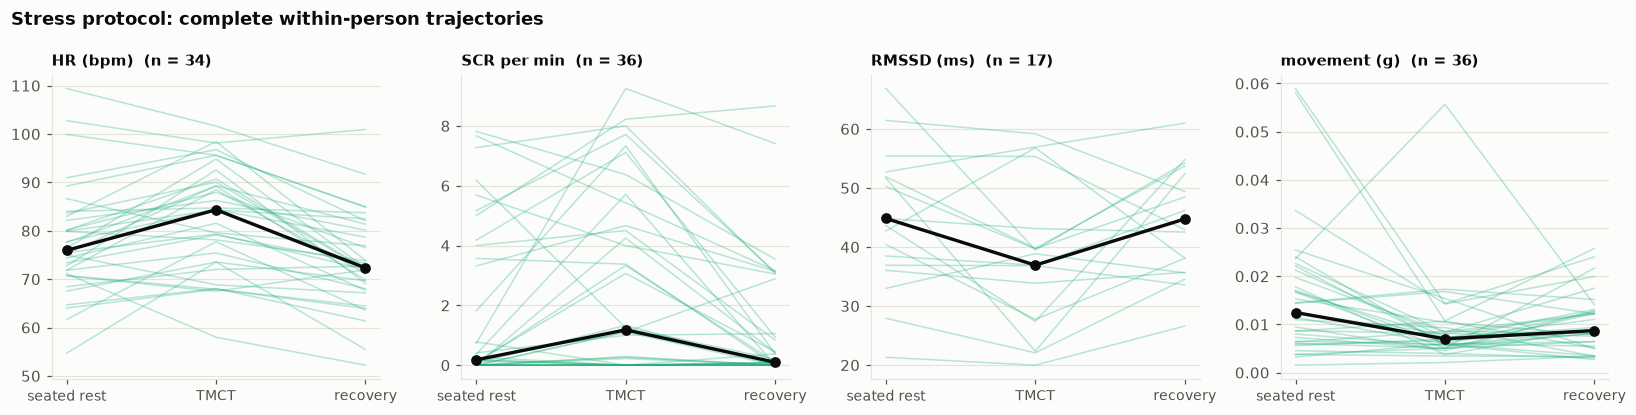

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8))
for ax, (f, lab, src) in zip(axes, [("hr_mean", "HR (bpm)", pm), ("eda_scr_rate", "SCR per min", pm),
                                   ("rmssd_ms", "RMSSD (ms)", hrv_pm), ("acc_movement", "movement (g)", pm)]):
    wide = src.pivot_table(index="subject_id", columns="state", values=f).reindex(columns=three)
    for _, r in wide.dropna().iterrows():
        ax.plot(range(3), r.values, color=C["STRESS"], alpha=0.3, lw=1)
    ax.plot(range(3), wide.median().values, color=P.TEXT, lw=2.2, marker="o")
    ax.set_xticks(range(3), ["seated rest", "TMCT", "recovery"], fontsize=9); ax.set_title(f"{lab}  (n = {len(wide.dropna())})", loc="left", fontsize=10)
    ax.grid(axis="x", visible=False)
fig.suptitle("Stress protocol: complete within-person trajectories", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); P.save(fig, "06_stress_protocol"); plt.show()

Within the same session:
- **HR rises during the TMCT and falls below the starting baseline during recovery** (TMCT +5.0 bpm; recovery −4.3 bpm
  vs baseline; TMCT → recovery −9.2 bpm, d_z −1.2). The initial "baseline" therefore was not fully at rest. It
  probably includes anticipatory arousal on arriving for a stress experiment. This is a common issue in stress protocols,
  and it means the true stress response is closer to the TMCT-vs-recovery contrast.
- **EDA level** rises during the TMCT (×1.6) and returns to baseline in recovery. **SCR rate** rises in the TMCT and drops
  in recovery (TMCT vs recovery d_z −0.72, Holm p = 0.006).
- **HRV.** Mean NN interval shortens by 76 ms during the TMCT (Holm p = 0.005), the beat-to-beat expression of the HR rise.
  **RMSSD falls by ~7 ms** (CI −13.5 to −1.8, d_z −0.58), consistent with vagal withdrawal, and recovers afterwards.
  After Holm correction across the whole family it is not significant: only 17–23 participants have enough clean beats.
  The direction is physiologically expected; the evidence is suggestive.
- Movement does not explain any of this: it is lower during the task than at baseline.

## 4 · Self-reported stress vs physiology

Repeated-measures correlation (Bakdash & Marusich, 2017): within-person association between the self-reported stress
of each block and the physiology measured in that block, after removing each person's average level.

In [6]:
from src.data.empatica import read_stress_levels
sl = read_stress_levels()
colmap = {"Baseline": "baseline", "Stroop": "stroop", "First Rest": "first_rest", "TMCT": "tmct", "Second Rest": "second_rest",
          "Real Opinion": "real_opinion", "Opposite Opinion": "opposite_opinion", "Subtract": "subtract"}
long = pd.concat([d.rename(columns=colmap).reset_index().melt(id_vars="subject_id", var_name="segment", value_name="self_report")
                  for d in sl.values()])
blk = m[m.condition == "STRESS"].groupby(["subject_id", "segment"])[["hr_mean", "eda_log", "eda_scr_rate"]].mean().reset_index()
blk.loc[blk.subject_id == "f14", :] = blk.loc[blk.subject_id == "f14", :]
j = long.merge(blk, on=["subject_id", "segment"], how="inner")
rm = pd.DataFrame([dict(physiology=FL.get(f, f), **repeated_measures_corr(j, "self_report", f)) for f in ["hr_mean", "eda_log", "eda_scr_rate"]])
rm.to_csv(PROCESSED / "stats_selfreport_rmcorr.csv", index=False)
rm.round(3)

,physiology,r_rm,dof,p,n_obs,n_subjects
0,HR mean,0.395,138,0.000,174,35
1,EDA tonic (log10 µS),0.182,232,0.005,269,36
2,SCR rate,0.115,232,0.079,269,36


Self-reported stress and physiology move together **within** people: blocks a participant rates as more stressful
also show higher HR (r_rm = 0.40, p < 0.001) and slightly higher EDA level (r_rm = 0.18, p = 0.005). SCR rate is not
significantly related (r_rm = 0.12). The wearable signal tracks perceived stress, but only moderately: HR explains about
16% of the within-person variance in self-report.

## 5 · Within-person vs between-person variability

ICC from a random-intercept model on the 30-s windows *within one state*: the share of window-to-window variance
explained by **who** the participant is. High ICC means people differ consistently (individual "set points"). Low ICC
means variability is mostly moment-to-moment.

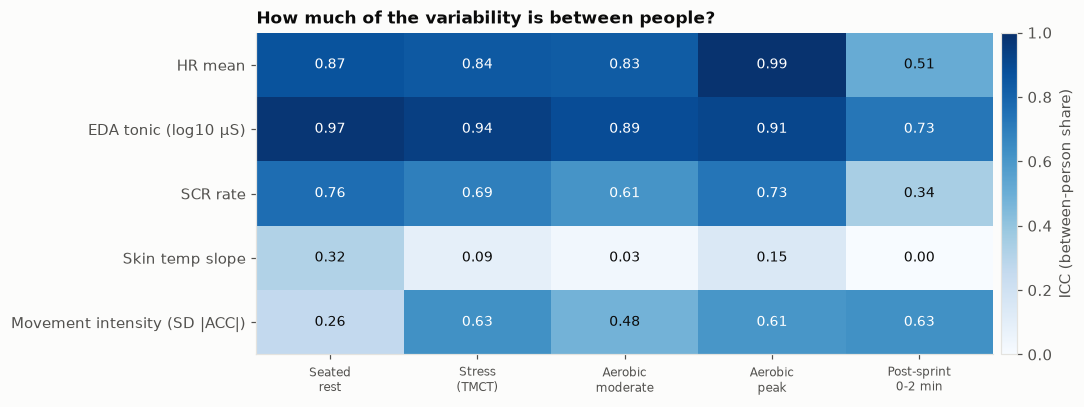

state,REST_SEATED,STRESS_TMCT,AEROBIC_MODERATE,AEROBIC_PEAK,POST_SPRINT
feature,,,,,
hr_mean,0.870,0.840,0.830,0.990,0.510
eda_log,0.970,0.940,0.890,0.910,0.730
eda_scr_rate,0.760,0.690,0.610,0.730,0.340
temp_slope,0.320,0.090,0.030,0.150,0.000
acc_movement,0.260,0.630,0.480,0.610,0.630


In [7]:
icc_rows = []
for s in ["REST_SEATED", "STRESS_TMCT", "AEROBIC_MODERATE", "AEROBIC_PEAK", "POST_SPRINT"]:
    d = m[m.analysis_state == s]
    for f in FEATS:
        icc_rows.append(dict(state=s, feature=f, icc=icc_within_state(d, f)))
icc = pd.DataFrame(icc_rows).pivot(index="feature", columns="state", values="icc").reindex(FEATS)[["REST_SEATED", "STRESS_TMCT", "AEROBIC_MODERATE", "AEROBIC_PEAK", "POST_SPRINT"]]
icc.to_csv(PROCESSED / "stats_icc.csv")
fig, ax = plt.subplots(figsize=(9, 3.8))
im = ax.imshow(icc.to_numpy(dtype=float), cmap="Blues", vmin=0, vmax=1, aspect="auto")
for i in range(icc.shape[0]):
    for jj in range(icc.shape[1]):
        v = icc.iloc[i, jj]
        ax.text(jj, i, "–" if not np.isfinite(v) else f"{v:.2f}", ha="center", va="center", fontsize=9, color="white" if v > 0.6 else P.TEXT)
ax.set_xticks(range(icc.shape[1]), [LABEL[s].replace(" ", "\n", 1) for s in icc.columns], fontsize=8)
ax.set_yticks(range(len(FEATS)), [FL[f] for f in FEATS]); ax.grid(False)
fig.colorbar(im, ax=ax, fraction=0.03, pad=0.01).set_label("ICC (between-person share)")
ax.set_title("How much of the variability is between people?", loc="left")
P.save(fig, "06_icc"); plt.show()
icc.round(2)

- **HR and EDA level are highly individual** (ICC 0.83–0.99 in most states). Most of the window-to-window variance is
  *between* people, not within a person. Absolute thresholds ("HR > X means stressed") therefore generalise poorly
  across people, and **participant-grouped validation is essential**: a model evaluated on windows from people it
  has already seen would mostly be recognising individuals.
- **SCR rate** is moderately individual (0.6–0.76), lower after sprints (0.34).
- **Skin-temperature slope** is essentially noise (ICC ≤ 0.32, ≈ 0–0.15 during exercise).
- Post-sprint HR has the lowest ICC (0.51): this is a transient recovery phase, where timing matters more than the person.

## 6 · Robustness checks

1. **Cohort:** the TMCT response computed separately in V1 (men, lab) and V2 (mostly women, remote).
2. **Quality filtering:** the same HR contrast with unfiltered Empatica HR.

In [8]:
wide = pm.pivot_table(index=["subject_id", "cohort"], columns="state", values="hr_mean").reset_index()
rob = []
for coh in ["V1", "V2"]:
    d = wide[wide.cohort == coh][["REST_SEATED", "STRESS_TMCT"]].dropna()
    rob.append(dict(check=f"TMCT − rest, cohort {coh}", **paired_effect(d.REST_SEATED.to_numpy(), d.STRESS_TMCT.to_numpy())))
raw = w[w.analysis_state.isin(["REST_SEATED", "STRESS_TMCT", "AEROBIC_PEAK"])].groupby(["subject_id", "analysis_state"]).hr_mean.mean().unstack()
for s in ["STRESS_TMCT", "AEROBIC_PEAK"]:
    d = raw[["REST_SEATED", s]].dropna()
    rob.append(dict(check=f"{s} − rest, UNFILTERED HR", **paired_effect(d.REST_SEATED.to_numpy(), d[s].to_numpy())))
filt = pm.pivot_table(index="subject_id", columns="state", values="hr_mean")
for s in ["STRESS_TMCT", "AEROBIC_PEAK"]:
    d = filt[["REST_SEATED", s]].dropna()
    rob.append(dict(check=f"{s} − rest, quality-filtered HR", **paired_effect(d.REST_SEATED.to_numpy(), d[s].to_numpy())))
rob = pd.DataFrame(rob); rob.to_csv(PROCESSED / "stats_robustness.csv", index=False)
rob[["check", "n", "mean_diff", "ci_low", "ci_high", "dz", "p_wilcoxon"]].round(3)

,check,n,mean_diff,ci_low,ci_high,dz,p_wilcoxon
0,"TMCT − rest, cohort V1",17,5.415,0.844,9.654,0.573,0.045
1,"TMCT − rest, cohort V2",17,4.585,1.294,7.968,0.629,0.035
2,"STRESS_TMCT − rest, UNFILTERED HR",35,2.182,-4.075,6.854,0.132,0.026
3,"AEROBIC_PEAK − rest, UNFILTERED HR",28,37.790,26.147,50.091,1.145,0.000
4,"STRESS_TMCT − rest, quality-filtered HR",34,5.000,2.177,7.773,0.601,0.002
5,"AEROBIC_PEAK − rest, quality-filtered HR",20,48.787,34.335,63.664,1.401,0.000


- **Cohort.** The TMCT HR response is nearly identical in V1 (+5.4 bpm, n = 17) and V2 (+4.6 bpm, n = 17), despite the
  differences in sex, setting and protocol version. The stress response is robust to these confounds.
- **Quality filtering matters.** With unfiltered Empatica HR, the TMCT effect shrinks to +2.2 bpm (CI −4.1 to +6.9) and is
  no longer clearly different from zero. With quality filtering it is +5.0 bpm (2.2–7.8). The artefactual windows
  add noise that hides a real effect. For the aerobic peak, the unfiltered estimate (+38 bpm) is *smaller* than the
  filtered one (+49 bpm): unfiltered data contain the flat or locked HR traces seen in Phase 1.

**Bottom line of the statistics.** Stress and exercise both activate the cardiovascular and sudomotor systems.
Exercise does so with an order-of-magnitude larger HR and EDA response, accompanied by movement. Stress does so with
the wrist *stiller* than at rest. The two exercise types are hard to distinguish on session averages. Physiology is
highly individual, so any classifier must be evaluated on unseen people (notebook 07).